In [15]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,BatchNormalization,Dropout,GlobalAveragePooling2D
from sklearn.metrics import classification_report,confusion_matrix
import seaborn as sns

In [2]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    "Garbage_Dataset/train",
    target_size=(IMG_SIZE,IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

validation_generator = test_datagen.flow_from_directory(
    "Garbage_Dataset/validation",
    target_size=(IMG_SIZE,IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)
test_generator = test_datagen.flow_from_directory(
    "Garbage_Dataset/test",
    target_size=(IMG_SIZE,IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print(train_generator.class_indices)

Found 2101 images belonging to 6 classes.
Found 446 images belonging to 6 classes.
Found 453 images belonging to 6 classes.
{'battery': 0, 'biological': 1, 'brown-glass': 2, 'cardboard': 3, 'clothes': 4, 'plastic': 5}


In [5]:
num_classes = train_generator.num_classes

alex = Sequential()
alex.add(Conv2D(96,(11,11),strides=4,activation='relu',input_shape=(224,224,3)))
alex.add(BatchNormalization())
alex.add(MaxPooling2D(pool_size=(3,3),strides=3))
alex.add(Conv2D(256,(5,5),padding='same',activation='relu'))
alex.add(BatchNormalization())
alex.add(MaxPooling2D(pool_size=(3,3),strides=2))
alex.add(Conv2D(384,(3,3),padding='same',activation='relu'))
alex.add(Conv2D(384,(3,3),padding='same',activation='relu'))
alex.add(Conv2D(384,(3,3),padding='same',activation='relu'))
alex.add(MaxPooling2D(pool_size=(3,3),strides=2))
alex.add(GlobalAveragePooling2D())
alex.add(Dense(512,activation='relu'))
alex.add(Dropout(0.5))
alex.add(Dense(num_classes,activation='softmax'))



C:\Users\ME\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
alex.compile(optimizer= Adam(learning_rate=0.001),loss='categorical_crossentropy',metrics=['accuracy'])
alex.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 54, 54, 96)          │          34,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 54, 54, 96)          │             384 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 18, 18, 96)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 18, 18, 256)         │         614,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 18, 18, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 8, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 8, 8, 384)           │         885,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 8, 8, 384)           │       1,327,488 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 8, 8, 384)           │       1,327,488 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 3, 3, 384)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 384)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         197,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │           3,078 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,391,302 (16.75 MB)

 Trainable params: 4,390,598 (16.75 MB)

 Non-trainable params: 704 (2.75 KB)

In [7]:
history= alex.fit(train_generator,validation_data=validation_generator,epochs=5)

Epoch 1/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 68s 983ms/step - accuracy: 0.4579 - loss: 1.5418 - val_accuracy: 0.2982 - val_loss: 1.7662
Epoch 2/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 43s 647ms/step - accuracy: 0.6126 - loss: 1.1512 - val_accuracy: 0.2735 - val_loss: 1.9537
Epoch 3/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 43s 644ms/step - accuracy: 0.6406 - loss: 1.0684 - val_accuracy: 0.3453 - val_loss: 2.4801
Epoch 4/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 43s 649ms/step - accuracy: 0.6782 - loss: 0.9499 - val_accuracy: 0.6323 - val_loss: 1.0319
Epoch 5/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 43s 647ms/step - accuracy: 0.7154 - loss: 0.8672 - val_accuracy: 0.6839 - val_loss: 0.9457


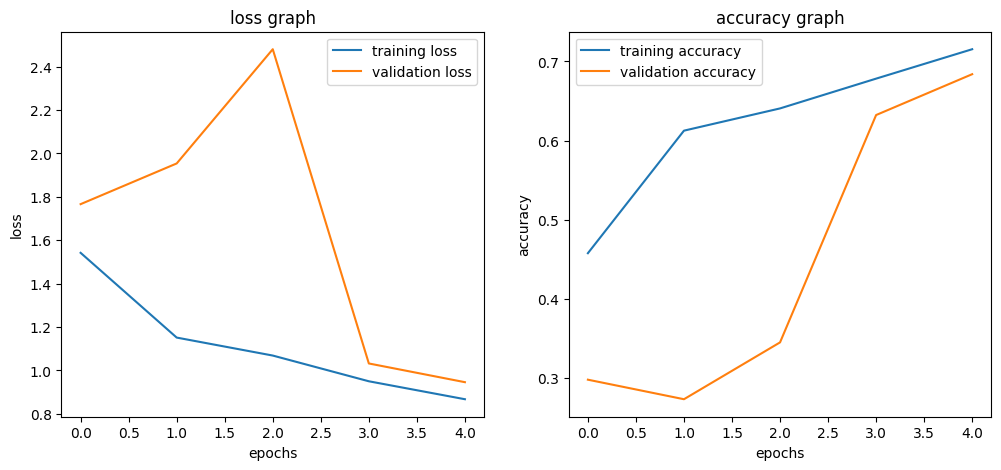

In [12]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(history.history['loss'],label='training loss')
plt.plot(history.history['val_loss'],label='validation loss')
plt.legend()
plt.title("loss graph")
plt.xlabel("epochs")
plt.ylabel("loss")


plt.subplot(1,2,2)

plt.plot(history.history['accuracy'],label='training accuracy')
plt.plot(history.history['val_accuracy'],label='validation accuracy')
plt.legend()
plt.title("accuracy graph")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.show()

In [14]:
loss,accuracy = alex.evaluate(test_generator)

print("loss:",loss)
print("accuracy:",accuracy)

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 151ms/step - accuracy: 0.6843 - loss: 0.9393
loss: 0.9393185377120972
accuracy: 0.684326708316803


15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 144ms/step


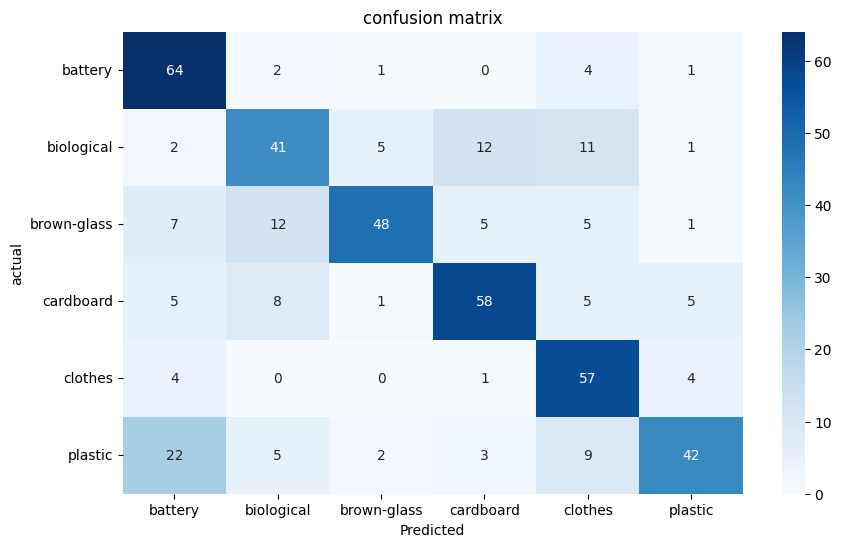

In [22]:
y_pred_prob = alex.predict(test_generator)

y_pred = np.argmax(y_pred_prob,axis=1)

y_true = test_generator.classes

class_names = list(test_generator.class_indices.keys())

cm = confusion_matrix(y_true,y_pred)

plt.figure(figsize=(10,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names,
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("actual")
plt.title("confusion matrix")

# plt.xticks(rotation=45)
# plt.yticks(rotation=45)
plt.show()

In [24]:
print(classification_report(y_true,y_pred,target_names=class_names))

              precision    recall  f1-score   support

     battery       0.62      0.89      0.73        72
  biological       0.60      0.57      0.59        72
 brown-glass       0.84      0.62      0.71        78
   cardboard       0.73      0.71      0.72        82
     clothes       0.63      0.86      0.73        66
     plastic       0.78      0.51      0.61        83

    accuracy                           0.68       453
   macro avg       0.70      0.69      0.68       453
weighted avg       0.71      0.68      0.68       453

